# 01 — Melbourne Housing: preços e qualidade dos dados
Projeto 02 de Fundamentos de IA — Grupo 09.

Fonte: [Melbourne Housing Snapshot](https://www.kaggle.com/datasets/dansbecker/melbourne-housing-snapshot).
A coluna Price representa o preço observado de venda; não é um custo de construção nem uma avaliação de preço justo.

Objetivo: usar scikit-learn para criar três classes de preço e depois aprender a prever
essas classes com uma árvore de decisão de raiz. Os dados são de Melbourne, não de Portugal.

In [1]:
from pathlib import Path
import json
import platform
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython import get_ipython
from IPython.display import display
from matplotlib_inline.backend_inline import set_matplotlib_formats
from libs.data import load_housing, PRICE_LABELS, FEATURES, prepare_partitions, HousingPreparation

get_ipython().run_line_magic("matplotlib", "inline")
set_matplotlib_formats("svg")
SEED = 42
houses = load_housing(download=True)
print(houses.attrs["source"])
print({"Python": platform.python_version(), "pandas": pd.__version__, "NumPy": np.__version__, "scikit-learn": sklearn.__version__})

{'dataset': 'dansbecker/melbourne-housing-snapshot', 'ficheiro': 'melb_data.csv', 'sha256': '3e449c3e95088da8a3a6b10331a5703f2c951d0740f317f97ed9baf0db1fd9f8', 'linhas_originais': 13580, 'duplicados_exatos_removidos': 0, 'preços_inválidos_removidos': 0, 'linhas_utilizadas': 13580}
{'Python': '3.11.6', 'pandas': '3.0.1', 'NumPy': '1.26.4', 'scikit-learn': '1.8.0'}


## Auditoria e metadados
A leitura regista o hash do CSV, remove apenas cópias exatas e exclui preços ausentes,
não finitos ou não positivos. As contagens abaixo permitem verificar o efeito dessa limpeza.
As unidades e o contexto devem ser consultados na página da fonte; aqui não se convertem preços para euros.

In [2]:
display(pd.DataFrame({
    "tipo": houses.dtypes.astype(str),
    "em_falta": houses.isna().sum(),
    "percentagem_em_falta": houses.isna().mean() * 100,
}))
display(houses[FEATURES + ["Price"]].head())
display(houses.select_dtypes(include="number").describe(percentiles=[0.01, 0.5, 0.99]).T)
print("Registos adicionais da mesma morada:", houses.duplicated(["Suburb", "Address"]).sum())

,tipo,em_falta,percentagem_em_falta
Suburb,str,0,0.000000
Address,str,0,0.000000
Rooms,int64,0,0.000000
Type,str,0,0.000000
Price,float64,0,0.000000
Method,str,0,0.000000
SellerG,str,0,0.000000
Date,str,0,0.000000
Distance,float64,0,0.000000
Postcode,float64,0,0.000000


,Rooms,Distance,Bathroom,Car,Landsize,BuildingArea,YearBuilt,Lattitude,Longtitude,Type,Price
0,2,2.5,1.0,1.0,202.0,NaN,NaN,-37.7996,144.9984,h,1480000.0
1,2,2.5,1.0,0.0,156.0,79.0,1900.0,-37.8079,144.9934,h,1035000.0
2,3,2.5,2.0,0.0,134.0,150.0,1900.0,-37.8093,144.9944,h,1465000.0
3,3,2.5,2.0,1.0,94.0,NaN,NaN,-37.7969,144.9969,h,850000.0
4,4,2.5,1.0,2.0,120.0,142.0,2014.0,-37.8072,144.9941,h,1600000.0


,count,mean,std,min,1%,50%,99%,max
Rooms,13580.0,2.937997e+00,0.955748,1.00000,1.000000,3.000000,5.000000e+00,1.000000e+01
Price,13580.0,1.075684e+06,639310.724296,85000.00000,300000.000000,903000.000000,3.338150e+06,9.000000e+06
Distance,13580.0,1.013778e+01,5.868725,0.00000,1.600000,9.200000,3.230000e+01,4.810000e+01
Postcode,13580.0,3.105302e+03,90.676964,3000.00000,3006.000000,3084.000000,3.429000e+03,3.977000e+03
Bedroom2,13580.0,2.914728e+00,0.965921,0.00000,1.000000,3.000000,5.000000e+00,2.000000e+01
Bathroom,13580.0,1.534242e+00,0.691712,0.00000,1.000000,1.000000,4.000000e+00,8.000000e+00
Car,13518.0,1.610075e+00,0.962634,0.00000,0.000000,2.000000,5.000000e+00,1.000000e+01
Landsize,13580.0,5.584161e+02,3990.669241,0.00000,0.000000,440.000000,2.959830e+03,4.330140e+05
BuildingArea,7130.0,1.519676e+02,541.014538,0.00000,7.580000,126.000000,4.664200e+02,4.451500e+04
YearBuilt,8205.0,1.964684e+03,37.273762,1196.00000,1880.000000,1970.000000,2.015000e+03,2.018000e+03


Registos adicionais da mesma morada: 114


## Distribuição do preço
O histograma em escala logarítmica ajuda a visualizar a cauda de imóveis mais caros.
É apenas uma representação: o K-Means que cria as classes usa o preço original.

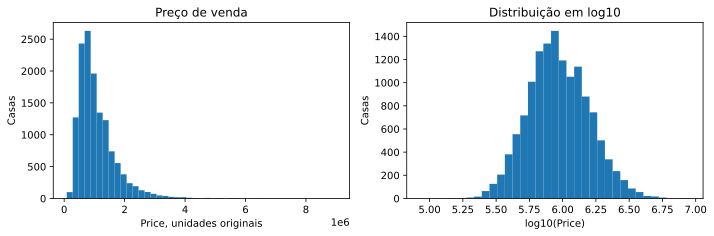

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].hist(houses["Price"], bins=45)
axes[0].set(title="Preço de venda", xlabel="Price, unidades originais", ylabel="Casas")
axes[1].hist(np.log10(houses["Price"]), bins=35)
axes[1].set(title="Distribuição em log10", xlabel="log10(Price)", ylabel="Casas")
plt.tight_layout()
plt.show()

## Variável-alvo proposta
Primeiro separam-se os imóveis em treino, validação e teste, mantendo vendas da mesma
morada no mesmo conjunto. Só os preços do treino são usados para ajustar KMeans(n_clusters=3).
Os centroides são ordenados para dar os nomes barato, normal e caro.

Estes nomes indicam grupos de preço absoluto neste dataset. «Barato» não significa
que uma casa esteja subavaliada para a sua zona ou características.

In [4]:
parts, bands = prepare_partitions(houses, seed=SEED)
classified = pd.concat(parts).sort_values("SourceRow")
display(pd.DataFrame({"classe": PRICE_LABELS, "centro_preço_treino": bands.centers_}))
display(classified.groupby("ClassePreco", observed=True)["Price"].agg(["count", "min", "median", "max"]))
print("Fronteiras entre centroides:", bands.boundaries_)

,classe,centro_preço_treino
0,barato,7.014559e+05
1,normal,1.465988e+06
2,caro,2.858575e+06


,count,min,median,max
ClassePreco,,,,
barato,8438,85000.0,705000.0,1082000.0
normal,4322,1085000.0,1400000.0,2162000.0
caro,820,2165000.0,2600000.0,9000000.0


Fronteiras entre centroides: [1083721.94045645 2162281.57638966]


## Decisões para a árvore
Usamos divisões, distância, casas de banho, estacionamento, áreas, ano de construção,
coordenadas e tipo de imóvel. Price, PriceClass e ClassePreco nunca entram nas entradas.
Também excluímos a morada, identificadores, data, vendedor e método de venda.

As medianas e as categorias são aprendidas apenas no treino. Há informação de área
de construção e ano em falta em parte dos imóveis; a imputação perde informação e é uma limitação.
A divisão por imóvel avalia novas moradas na mesma distribuição histórica, não previsão futura
nem aplicação a Portugal.

## Leitura dos resultados desta execução
A base contém 13 580 vendas, sem preços em falta nem duplicados exatos. Há 114 registos adicionais da mesma morada; a separação mantém-nos juntos. BuildingArea falta em 6 450 registos e YearBuilt em 5 375, pelo que a imputação é uma decisão com impacto real.

A base contém 8 438 casas no grupo barato, 4 322 no normal e 820 no caro. Não se pretendia formar três grupos com o mesmo tamanho. As classes dependem da distribuição desta base e não medem se um imóvel é um bom negócio.

Existem 17 áreas de construção zero, 1 939 áreas de terreno zero e um ano mínimo de 1196. Estes valores exigem revisão do significado na fonte; zero de terreno pode ter um significado próprio em apartamentos. Foram assinalados, sem inventar correções nem remover extremos automaticamente.